# Activity 01: Introduction to Reinforcement Learning

**AI-2.5 Modern Artificial Intelligence**

---

## 🎯 Objective

Build your first reinforcement learning agent and understand the agent-environment interaction loop.

**What You'll Learn:**
- How agents interact with environments (observation → action → reward → next observation)
- The CartPole balancing task
- Random baseline performance
- Simple exploration strategies (epsilon-greedy)
- Performance metrics and visualization

## 📍 Where to do your work

This notebook runs on **CPU or Colab** — CartPole is a tiny environment, no GPU needed. Gymnasium has replaced the deprecated `gym` package — make sure imports use `import gymnasium as gym`.

| Surface | Role | Edit? |
|---|---|---|
| This `.ipynb` | Canonical TODO surface — **edit this** | ✅ Yes |
| Random Baseline Agent cell (Section 4) | Working scaffolding — read it, don't edit | ❌ No |
| TODO 1–4 cells | Where you implement epsilon-greedy + analysis | ✅ Yes |

The Random Baseline Agent cell is **scaffolding** — it shows you the agent-environment loop in its simplest form. Run it, watch how a random agent performs on CartPole (typically <30 steps before the pole falls), then improve it via TODO 1–4.

**Your TODOs:**
- ⚠️ TODO 1: Implement epsilon-greedy exploration
- ⚠️ TODO 2: Add action frequency analysis
- ⚠️ TODO 3: Compare policies
- ⚠️ TODO 4: Sweep epsilon and plot mean reward

---

## 1. Installation

Install required packages for Gymnasium (OpenAI Gym successor) and visualization.

In [18]:
# Install into this notebook kernel's Python, not whichever pip happens to be on PATH.
import sys
!{sys.executable} -m pip install gymnasium[classic_control] matplotlib imageio imageio-ffmpeg numpy ipykernel

# Verify imports so a failed install cannot appear to have succeeded.
import gymnasium
import numpy
import matplotlib
import imageio
import IPython
print(f"✅ Installation and imports verified with {sys.executable}")

✅ Installation and imports verified with c:\Users\benlo\telebort\venv\Scripts\python.exe


## 2. Imports

Import all necessary libraries for RL experiments.

In [19]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import imageio
from IPython.display import Video, display
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

print("✅ Imports successful!")
print(f"Gymnasium version: {gym.__version__}")

✅ Imports successful!
Gymnasium version: 1.4.0


## 3. Understanding CartPole Environment

**CartPole-v1** is a classic RL benchmark:
- **Goal**: Balance a pole on a moving cart
- **Observation Space**: 4 continuous values
  - Cart position: [-4.8, 4.8]
  - Cart velocity: [-∞, ∞]
  - Pole angle: [-0.418, 0.418] radians (~24 degrees)
  - Pole angular velocity: [-∞, ∞]
- **Action Space**: 2 discrete actions
  - 0: Push cart to the left
  - 1: Push cart to the right
- **Reward**: +1 for every timestep the pole stays upright
- **Episode Termination**:
  - Pole angle > ±12 degrees
  - Cart position > ±2.4 units
  - Episode length > 500 steps
- **Success**: Average reward ≥ 475 over 100 episodes

In [20]:
# Create environment and inspect it
env = gym.make('CartPole-v1', render_mode='rgb_array')

print("🎮 CartPole Environment:")
print(f"  Observation space: {env.observation_space}")
print(f"  Action space: {env.action_space}")
print(f"  Action meanings: 0=Left, 1=Right")

# Sample a random state
observation, info = env.reset(seed=42)
print(f"\n📊 Sample observation: {observation}")
print(f"  [cart_pos, cart_vel, pole_angle, pole_vel]")

env.close()

🎮 CartPole Environment:
  Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
  Action space: Discrete(2)
  Action meanings: 0=Left, 1=Right

📊 Sample observation: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
  [cart_pos, cart_vel, pole_angle, pole_vel]


## 4. Random Baseline Agent (Pre-Built)

Let's start with the simplest possible agent: one that takes **random actions**.

This serves as our **baseline** for comparison.

In [21]:
class RandomAgent:
    """Agent that selects actions uniformly at random."""
    
    def __init__(self, action_space):
        self.action_space = action_space
    
    def select_action(self, observation):
        """Select a random action (50% left, 50% right)."""
        return self.action_space.sample()


def run_episode(env, agent, render=False, max_steps=500):
    """
    Run a single episode with the given agent.
    
    Returns:
        total_reward: Sum of rewards received
        episode_length: Number of steps taken
        frames: List of rendered frames (if render=True)
    """
    observation, info = env.reset()
    total_reward = 0
    frames = []
    
    for step in range(max_steps):
        # Agent selects action
        action = agent.select_action(observation)
        
        # Environment responds
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        
        # Save frame for video
        if render:
            frames.append(env.render())
        
        # Check if episode ended
        if terminated or truncated:
            break
    
    return total_reward, step + 1, frames


print("✅ Random agent class defined!")

✅ Random agent class defined!


## 5. Test Random Agent

Let's run the random agent for 100 episodes and track performance.

In [22]:
# Create environment and agent
env = gym.make('CartPole-v1', render_mode='rgb_array')
random_agent = RandomAgent(env.action_space)

# Run experiments
num_episodes = 100
rewards = []
episode_lengths = []

print("🎮 Running random agent for 100 episodes...")
for episode in range(num_episodes):
    reward, length, _ = run_episode(env, random_agent)
    rewards.append(reward)
    episode_lengths.append(length)
    
    if (episode + 1) % 20 == 0:
        print(f"  Episode {episode + 1}/100 - Reward: {reward:.1f}, Length: {length}")

env.close()

# Statistics
print("\n📊 Random Agent Performance:")
print(f"  Average reward: {np.mean(rewards):.2f} ± {np.std(rewards):.2f}")
print(f"  Min reward: {np.min(rewards):.1f}")
print(f"  Max reward: {np.max(rewards):.1f}")
print(f"  Average episode length: {np.mean(episode_lengths):.2f} steps")
print(f"  Success rate (reward ≥ 200): {np.mean(np.array(rewards) >= 200) * 100:.1f}%")

🎮 Running random agent for 100 episodes...
  Episode 20/100 - Reward: 13.0, Length: 13
  Episode 40/100 - Reward: 15.0, Length: 15
  Episode 60/100 - Reward: 24.0, Length: 24
  Episode 80/100 - Reward: 34.0, Length: 34
  Episode 100/100 - Reward: 8.0, Length: 8

📊 Random Agent Performance:
  Average reward: 21.82 ± 12.96
  Min reward: 8.0
  Max reward: 89.0
  Average episode length: 21.82 steps
  Success rate (reward ≥ 200): 0.0%


## 6. Visualize Random Agent Performance

Create plots showing reward distribution and learning curve.

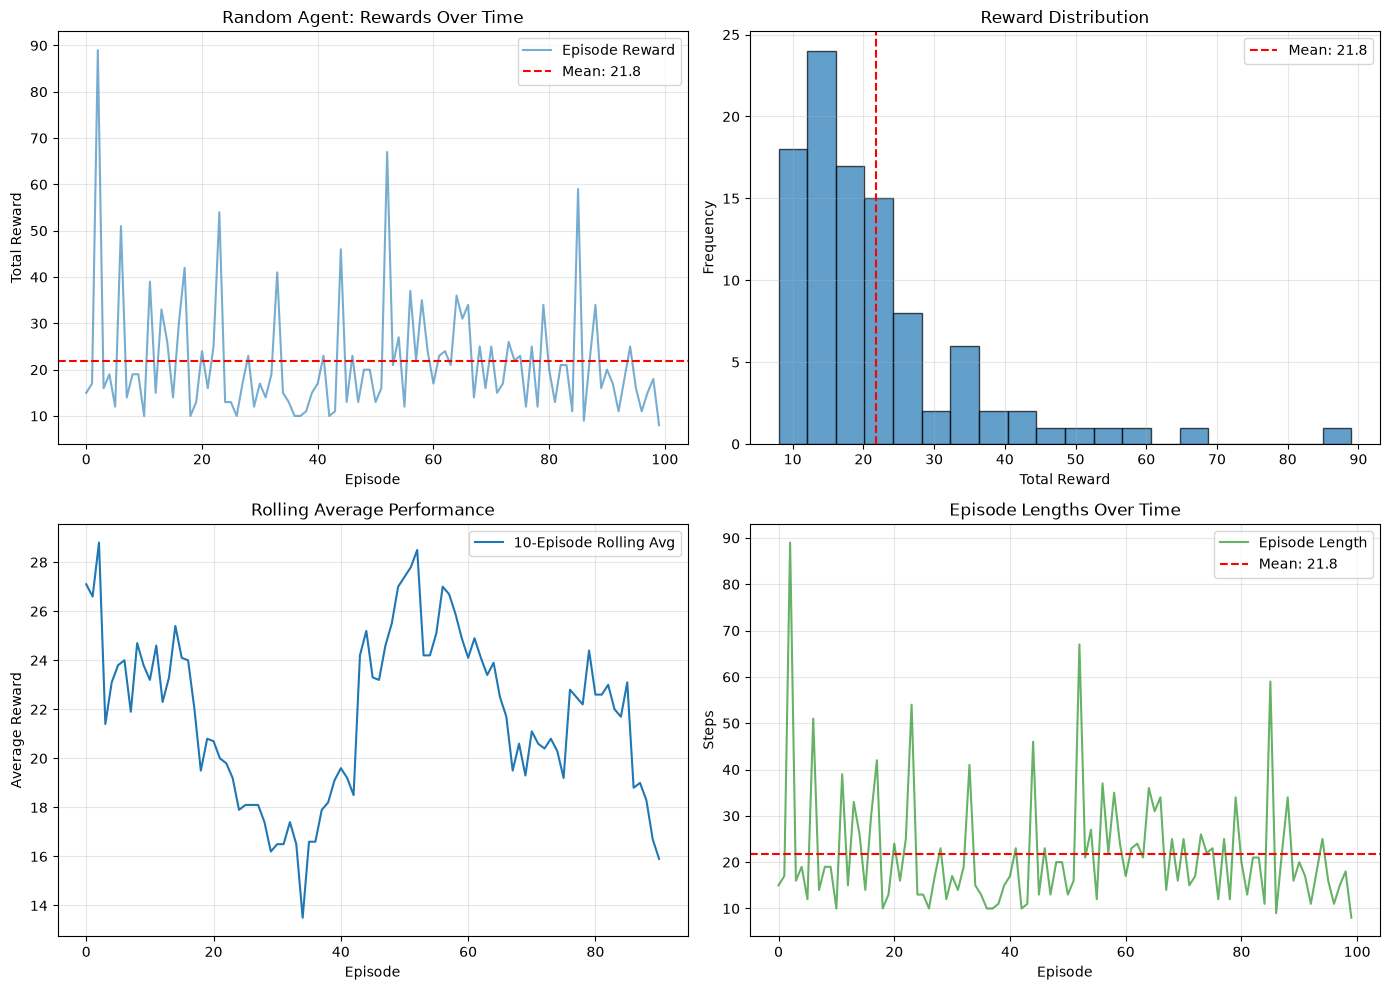

✅ Visualization complete!


In [23]:
# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Reward over episodes
axes[0, 0].plot(rewards, alpha=0.6, label='Episode Reward')
axes[0, 0].axhline(y=np.mean(rewards), color='r', linestyle='--', label=f'Mean: {np.mean(rewards):.1f}')
axes[0, 0].set_xlabel('Episode')
axes[0, 0].set_ylabel('Total Reward')
axes[0, 0].set_title('Random Agent: Rewards Over Time')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Reward distribution
axes[0, 1].hist(rewards, bins=20, edgecolor='black', alpha=0.7)
axes[0, 1].axvline(x=np.mean(rewards), color='r', linestyle='--', label=f'Mean: {np.mean(rewards):.1f}')
axes[0, 1].set_xlabel('Total Reward')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Reward Distribution')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Rolling average (window=10)
window = 10
rolling_avg = np.convolve(rewards, np.ones(window)/window, mode='valid')
axes[1, 0].plot(rolling_avg, label=f'{window}-Episode Rolling Avg')
axes[1, 0].set_xlabel('Episode')
axes[1, 0].set_ylabel('Average Reward')
axes[1, 0].set_title('Rolling Average Performance')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Episode lengths
axes[1, 1].plot(episode_lengths, alpha=0.6, color='green', label='Episode Length')
axes[1, 1].axhline(y=np.mean(episode_lengths), color='r', linestyle='--', 
                   label=f'Mean: {np.mean(episode_lengths):.1f}')
axes[1, 1].set_xlabel('Episode')
axes[1, 1].set_ylabel('Steps')
axes[1, 1].set_title('Episode Lengths Over Time')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Visualization complete!")

## 7. Record Video of Random Agent

Let's record a video of the random agent in action.

In [24]:
# Record one episode
env = gym.make('CartPole-v1', render_mode='rgb_array')
random_agent = RandomAgent(env.action_space)

reward, length, frames = run_episode(env, random_agent, render=True)
env.close()

# Save beside the notebook so the same cell works on Windows, macOS, Linux, and Colab.
from pathlib import Path
video_path = Path.cwd() / 'random_agent.mp4'
imageio.mimsave(video_path, frames, fps=30)

print(f"📹 Video saved: {video_path}")
print(f"Episode reward: {reward}, Length: {length} steps")

# Display inline where the notebook frontend supports video output.
display(Video(str(video_path), width=400))

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


📹 Video saved: c:\Users\benlo\telebort\Al2.5\project1\activity-07-your-first-rl-agent\random_agent.mp4
Episode reward: 20.0, Length: 20 steps


---

## 🛠️ TODO 1: Implement Epsilon-Greedy Agent (Medium)

**Your Task**: Create an agent that uses epsilon-greedy exploration.

**Strategy**:
- With probability ε (epsilon): take a random action (explore)
- With probability 1-ε: take a heuristic action (exploit)

**Heuristic**: 
- If pole is leaning left (angle < 0), push cart left (action 0)
- If pole is leaning right (angle > 0), push cart right (action 1)
- This simple rule helps balance the pole!

**Hint**: `observation[2]` contains the pole angle in radians

In [25]:
class EpsilonGreedyAgent:
    """Agent that uses epsilon-greedy exploration with a simple heuristic."""
    
    def __init__(self, action_space, epsilon=0.3):
        """
        Initialize epsilon-greedy agent.
        
        Args:
            action_space: Gymnasium action space
            epsilon: Probability of taking random action (0.0 - 1.0)
        """
        self.action_space = action_space
        self.epsilon = epsilon
    
    def select_action(self, observation):
        """
        Select action using epsilon-greedy strategy.
        
        Args:
            observation: [cart_pos, cart_vel, pole_angle, pole_vel]
        
        Returns:
            action: 0 (left) or 1 (right)
        """
        # TODO: Implement epsilon-greedy logic here
        # Exploration samples from the action space; exploitation follows the pole angle.
        if np.random.random() < self.epsilon:
            return self.action_space.sample()
        pole_angle = observation[2]
        return 0 if pole_angle < 0 else 1


# Test your implementation
print("🧪 Testing EpsilonGreedyAgent...")
env = gym.make('CartPole-v1', render_mode='rgb_array')
epsilon_agent = EpsilonGreedyAgent(env.action_space, epsilon=0.3)

# Run a few test episodes
test_rewards = []
for _ in range(10):
    reward, length, _ = run_episode(env, epsilon_agent)
    test_rewards.append(reward)

env.close()

print(f"\n📊 Epsilon-Greedy Agent (ε=0.3) - Test Results:")
print(f"  Average reward: {np.mean(test_rewards):.2f} ± {np.std(test_rewards):.2f}")
print(f"  Random baseline was: {np.mean(rewards):.2f}")

if np.mean(test_rewards) > np.mean(rewards):
    improvement = ((np.mean(test_rewards) - np.mean(rewards)) / np.mean(rewards)) * 100
    print(f"  ✅ Improvement: +{improvement:.1f}% over random baseline!")
else:
    print("  ⚠️ Performance is not better than random. Check your heuristic logic!")

🧪 Testing EpsilonGreedyAgent...

📊 Epsilon-Greedy Agent (ε=0.3) - Test Results:
  Average reward: 30.20 ± 15.28
  Random baseline was: 21.82
  ✅ Improvement: +38.4% over random baseline!


### Run Full Evaluation of Epsilon-Greedy Agent

Once your implementation works, run 100 episodes for thorough evaluation.

In [26]:
# Full evaluation (only run after TODO 1 is complete)
env = gym.make('CartPole-v1', render_mode='rgb_array')
epsilon_agent = EpsilonGreedyAgent(env.action_space, epsilon=0.3)

epsilon_rewards = []
print("🎮 Running epsilon-greedy agent for 100 episodes...")
for episode in range(100):
    reward, length, _ = run_episode(env, epsilon_agent)
    epsilon_rewards.append(reward)
    
    if (episode + 1) % 20 == 0:
        print(f"  Episode {episode + 1}/100 - Reward: {reward:.1f}")

env.close()

print("\n📊 Final Results:")
print(f"  Random baseline: {np.mean(rewards):.2f} ± {np.std(rewards):.2f}")
print(f"  Epsilon-greedy (ε=0.3): {np.mean(epsilon_rewards):.2f} ± {np.std(epsilon_rewards):.2f}")
print(f"  Improvement: {((np.mean(epsilon_rewards) - np.mean(rewards)) / np.mean(rewards)) * 100:.1f}%")

🎮 Running epsilon-greedy agent for 100 episodes...
  Episode 20/100 - Reward: 53.0
  Episode 40/100 - Reward: 43.0
  Episode 60/100 - Reward: 54.0
  Episode 80/100 - Reward: 78.0
  Episode 100/100 - Reward: 25.0

📊 Final Results:
  Random baseline: 21.82 ± 12.96
  Epsilon-greedy (ε=0.3): 43.87 ± 20.19
  Improvement: 101.1%


---

## 🛠️ TODO 2: Action Frequency Analysis (Easy)

**Your Task**: Track how often the agent takes each action and visualize the distribution.

**Requirements**:
1. Modify `run_episode()` to track actions taken
2. Create a function to count left (0) vs right (1) actions
3. Create a bar chart comparing action frequencies
4. Calculate action balance ratio

**Hint**: You'll need to modify the `run_episode()` function to return action counts.

Left actions: 447; right actions: 468
Action balance ratio (min/max): 0.955


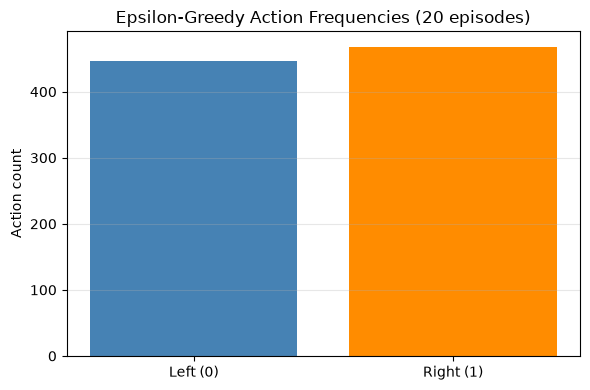

In [27]:
def run_episode_with_actions(env, agent, max_steps=500):
    """
    Run episode and track actions taken.
    
    Returns:
        total_reward: Sum of rewards
        episode_length: Number of steps
        actions: List of actions taken [0, 1, 0, 1, ...]
    """
    observation, info = env.reset()
    total_reward = 0
    actions = []  # Track all actions
    
    # TODO: Implement action tracking
    # Hint: Append each action to the 'actions' list
    
    for step in range(max_steps):
        action = agent.select_action(observation)
        # TODO: Track this action
        actions.append(int(action))
        
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        
        if terminated or truncated:
            break
    
    return total_reward, step + 1, actions


def analyze_actions(actions):
    """
    Analyze action distribution.
    
    Args:
        actions: List of actions [0, 1, 0, 1, ...]
    
    Returns:
        left_count: Number of left actions (0)
        right_count: Number of right actions (1)
        balance_ratio: min/max ratio (1.0 = perfectly balanced)
    """
    # TODO: Count left (0) and right (1) actions
    # Hint: Use actions.count(0) and actions.count(1)
    if not actions:
        raise ValueError("Cannot analyze an empty action sequence.")
    if any(action not in (0, 1) for action in actions):
        raise ValueError("Actions must be either 0 (left) or 1 (right).")
    left_count = actions.count(0)
    right_count = actions.count(1)
    balance_ratio = min(left_count, right_count) / max(left_count, right_count)
    return left_count, right_count, balance_ratio


# Test action tracking
env = gym.make('CartPole-v1', render_mode='rgb_array')
agent = EpsilonGreedyAgent(env.action_space, epsilon=0.3)

# TODO: Run 20 episodes and collect all actions
all_actions = []
for _ in range(20):
    _, _, episode_actions = run_episode_with_actions(env, agent)
    all_actions.extend(episode_actions)

env.close()

# TODO: Analyze and visualize
# Create bar chart showing left vs right action counts
left_count, right_count, balance_ratio = analyze_actions(all_actions)
print(f"Left actions: {left_count}; right actions: {right_count}")
print(f"Action balance ratio (min/max): {balance_ratio:.3f}")

plt.figure(figsize=(6, 4))
plt.bar(["Left (0)", "Right (1)"], [left_count, right_count], color=["steelblue", "darkorange"])
plt.ylabel("Action count")
plt.title("Epsilon-Greedy Action Frequencies (20 episodes)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


---

## 🛠️ TODO 3: Policy Comparison (Hard)

**Your Task**: Compare three different policies:
1. **Random**: Completely random actions (baseline)
2. **Epsilon-Greedy (ε=0.3)**: Your implementation from TODO 1
3. **Pure Heuristic (ε=0.0)**: Always use the heuristic, no randomness

**Requirements**:
- Run each policy for 100 episodes
- Track: average reward, success rate (≥200 reward), max reward
- Create comparison table
- Create side-by-side bar charts
- Write 2-3 sentence analysis of results

🧪 Comparing three policies...

Policy                             Mean ± Std   Success rate      Max
----------------------------------------------------------------------
Random                       23.82 ± 16.65            0.0%    136.0
Epsilon-Greedy (ε=0.3)       42.26 ± 21.86            0.0%    111.0
Pure Heuristic (ε=0.0)       41.37 ± 8.27             0.0%     62.0


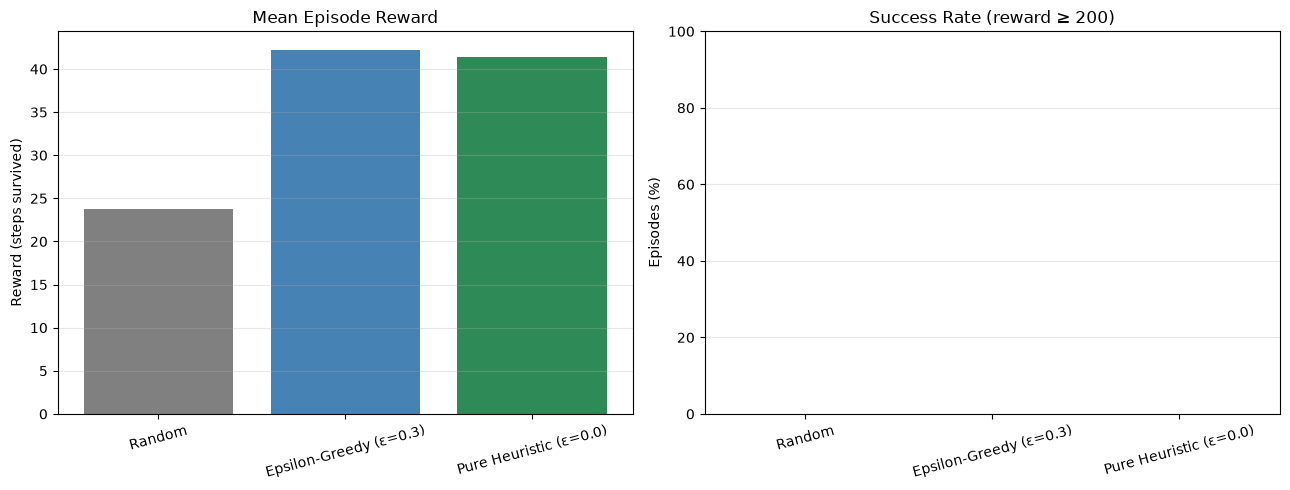


📝 Analysis:
Epsilon-Greedy (ε=0.3) had the highest mean reward (42.3), compared with 23.8 for the random baseline.
Remark: epsilon (ε) is the chance of choosing a random action; ε=0.3 explores randomly 30% of the time, while ε=0 always follows the heuristic.
The success-rate chart complements the mean because occasional long episodes can raise an average even when most trials end early.


In [17]:
# TODO: Define evaluation function
def evaluate_policy(agent, num_episodes=100):
    """
    Evaluate a policy over multiple episodes.
    
    Returns:
        results: dict with 'rewards', 'mean', 'std', 'success_rate', 'max'
    """
    if num_episodes <= 0:
        raise ValueError("num_episodes must be a positive integer.")

    env = gym.make('CartPole-v1')
    try:
        episode_rewards = [run_episode(env, agent)[0] for _ in range(num_episodes)]
    finally:
        env.close()

    reward_array = np.asarray(episode_rewards, dtype=float)
    return {
        'rewards': episode_rewards,
        'mean': float(np.mean(reward_array)),
        'std': float(np.std(reward_array)),
        'success_rate': float(np.mean(reward_array >= 200)),
        'max': float(np.max(reward_array)),
    }


# TODO: Test three policies
print("🧪 Comparing three policies...\n")

# 1. Random policy
policy_env = gym.make('CartPole-v1')
policies = {
    'Random': RandomAgent(policy_env.action_space),
    'Epsilon-Greedy (ε=0.3)': EpsilonGreedyAgent(policy_env.action_space, epsilon=0.3),
    'Pure Heuristic (ε=0.0)': EpsilonGreedyAgent(policy_env.action_space, epsilon=0.0),
}
policy_env.close()

policy_results = {name: evaluate_policy(agent, num_episodes=100)
                  for name, agent in policies.items()}

# TODO: Create comparison table
# success_rate is stored as a fraction and formatted here as a percentage.
print(f"{'Policy':<26} {'Mean ± Std':>18} {'Success rate':>14} {'Max':>8}")
print('-' * 70)
for name, result in policy_results.items():
    print(f"{name:<26} {result['mean']:>7.2f} ± {result['std']:<7.2f} "
          f"{result['success_rate'] * 100:>12.1f}% {result['max']:>8.1f}")

# TODO: Create visualization
# Side-by-side bar charts compare both survival reward and the success threshold.
policy_names = list(policy_results)
mean_rewards = [policy_results[name]['mean'] for name in policy_names]
success_rates = [policy_results[name]['success_rate'] * 100 for name in policy_names]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(policy_names, mean_rewards, color=['gray', 'steelblue', 'seagreen'])
axes[0].set_title('Mean Episode Reward')
axes[0].set_ylabel('Reward (steps survived)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', alpha=0.3)
axes[1].bar(policy_names, success_rates, color=['gray', 'steelblue', 'seagreen'])
axes[1].set_title('Success Rate (reward ≥ 200)')
axes[1].set_ylabel('Episodes (%)')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# TODO: Write analysis
print("\n📝 Analysis:")
best_policy = max(policy_results, key=lambda name: policy_results[name]['mean'])
random_mean = policy_results['Random']['mean']
best_mean = policy_results[best_policy]['mean']
print(f"{best_policy} had the highest mean reward ({best_mean:.1f}), "
      f"compared with {random_mean:.1f} for the random baseline.")
print("Remark: epsilon (ε) is the chance of choosing a random action; "
      "ε=0.3 explores randomly 30% of the time, while ε=0 always follows the heuristic.")
print("The success-rate chart complements the mean because occasional long episodes "
      "can raise an average even when most trials end early.")

---

## 🛠️ TODO 4: Sweep Epsilon (Medium)

Evaluate epsilon values from 0.0 through 1.0 in steps of 0.1, using 50 episodes for each value. The sweep shows how exploration changes average performance; because each estimate is based on a finite number of episodes, the highest point is an empirical optimum rather than a guarantee for every run.

The highlighted point is the epsilon with the highest measured mean reward in this sweep.

ε=0.0: mean reward 42.50 ± 8.97
ε=0.1: mean reward 42.62 ± 15.96
ε=0.2: mean reward 48.40 ± 22.04
ε=0.3: mean reward 39.16 ± 16.44
ε=0.4: mean reward 41.22 ± 18.12
ε=0.5: mean reward 41.68 ± 27.73
ε=0.6: mean reward 35.50 ± 26.94
ε=0.7: mean reward 30.68 ± 19.52
ε=0.8: mean reward 30.26 ± 17.12
ε=0.9: mean reward 30.32 ± 17.42
ε=1.0: mean reward 20.42 ± 9.57


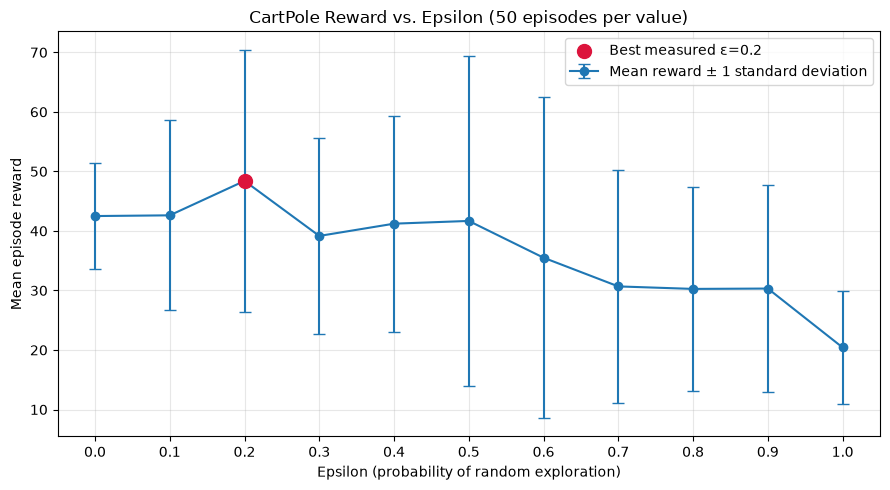


Best measured epsilon: 0.2 (mean reward 48.40)


In [16]:
# TODO: Sweep epsilon and plot mean reward
epsilon_values = np.round(np.linspace(0.0, 1.0, 11), 1)
sweep_means = []
sweep_stds = []
sweep_env = gym.make('CartPole-v1')

try:
    for epsilon in epsilon_values:
        sweep_agent = EpsilonGreedyAgent(sweep_env.action_space, epsilon=float(epsilon))
        sweep_result = evaluate_policy(sweep_agent, num_episodes=50)
        sweep_means.append(sweep_result['mean'])
        sweep_stds.append(sweep_result['std'])
        print(f"ε={epsilon:.1f}: mean reward {sweep_result['mean']:.2f} "
              f"± {sweep_result['std']:.2f}")
finally:
    sweep_env.close()

best_index = int(np.argmax(sweep_means))
best_epsilon = float(epsilon_values[best_index])
best_sweep_mean = sweep_means[best_index]

plt.figure(figsize=(9, 5))
plt.errorbar(epsilon_values, sweep_means, yerr=sweep_stds, marker='o', capsize=4,
             label='Mean reward ± 1 standard deviation')
plt.scatter([best_epsilon], [best_sweep_mean], color='crimson', s=100, zorder=3,
            label=f'Best measured ε={best_epsilon:.1f}')
plt.xticks(epsilon_values)
plt.xlabel('Epsilon (probability of random exploration)')
plt.ylabel('Mean episode reward')
plt.title('CartPole Reward vs. Epsilon (50 episodes per value)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
print(f"\nBest measured epsilon: {best_epsilon:.1f} "
      f"(mean reward {best_sweep_mean:.2f})")

---

## 9. Summary and Key Insights

### What You Learned:

1. **Agent-Environment Loop**:
   - Observation → Action → Reward → Next Observation
   - This is the fundamental interaction pattern in RL

2. **Exploration vs Exploitation**:
   - Random exploration discovers new strategies
   - Greedy exploitation uses known good strategies
   - Epsilon-greedy balances both

3. **Performance Metrics**:
   - Average reward: Overall performance
   - Success rate: Percentage of successful episodes
   - Episode length: How long the agent survived

4. **Simple Heuristics Work**:
   - A basic "lean left → push left" rule significantly improves over random
   - But it's not perfect - we can do better with learning!

### Next Steps:

In **Activity 02: Q-Learning**, you'll learn how agents can:
- **Learn optimal policies** from experience (no hand-coded heuristics!)
- **Estimate action values** for each state
- **Improve over time** through trial and error

---

## 🎉 Congratulations!

You've built your first RL agent and compared different exploration strategies. You now understand:
- How RL agents interact with environments
- The importance of balancing exploration and exploitation
- How to evaluate and visualize agent performance

**Keep experimenting!** Try different epsilon values, improve the heuristic, or test on other environments.


## 🪞 Reflect on Your Work

Answer in 2-3 sentences each, in your lesson note's **Investigation** section (click **Take Notes** at the top of the lesson page if you don't have a note yet). Your tutor reads these as part of grading.

1. **What did you learn that you didn't know before?** Name the most surprising thing — a planted bug you noticed, a metric that lied to you, a hyperparameter that mattered more than you expected.
2. **How did you collaborate with AI?** If you used Claude / ChatGPT / Cursor / Copilot, what part of the work did *you* contribute — the prompt, the verification of the data, the diagnosis of the bug, the design decision? If you didn't use AI, what was the hardest thing to figure out alone?
3. **How do you know your code works?** Describe one specific thing you did to confirm — a plot you read, an assertion you wrote, a side-by-side you ran with the planted-bug version vs your fix.

> AI is a great collaborator. Owning your investigation, verifying the output, and explaining your design choices is what *learning* looks like in this course.

## Submit

When the Verify / Investigation checklist is green, head to **[/learn/ai25/certification](/learn/ai25/certification)** and submit your notebook link. Make sure your **Investigation** note section covers the planted bugs you found, what you fixed, and what you'd still investigate if you had another hour.